# Étude de cas : analyse des accidents de la route avec PySpark

**Cours :** Fondements et Application de Big Data

**Objectif :** refaire l'étude [*Big Data Analysis of Road Crash Data using PySpark with PySpark Tutorial*](https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588) de Rakesh Nain.

## 1. Problème et données

On dispose des accidents de la route d'Australie-Méridionale de 2012 à 2019, publiés par le Department of Planning, Transport and Infrastructure (DPTI). Les fichiers viennent du [dépôt GitHub de l'auteur](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial) : 16 fichiers CSV, 77 Mo au total, téléchargés par la cellule ci-dessous.

- `crash_data/` : une ligne par accident (lieu, date, nombre de victimes, gravité, alcool, drogues...) ;
- `units_data/` : une ligne par véhicule impliqué (type, année, sexe et âge du conducteur, permis...).

Les deux jeux sont reliés par la colonne `REPORT_ID`. Le jour exact n'est pas publié : une date s'écrit année-mois-jour de la semaine (par exemple 2017-January-Sunday).

On répond aux questions de l'étude avec les trois structures de données de PySpark (RDD, DataFrame, SparkSQL), on vérifie les résultats avec ceux publiés dans l'article, puis on compare les trois structures sur les mêmes requêtes.

In [1]:
import os, urllib.request

DEPOT = "https://raw.githubusercontent.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/main"
for dossier, type_fichier in [("crash_data", "Crash"), ("units_data", "Units")]:
    os.makedirs(dossier, exist_ok=True)
    for annee in range(2012, 2020):
        fichier = f"{dossier}/{annee}_DATA_SA_{type_fichier}.csv"
        if not os.path.exists(fichier):
            urllib.request.urlretrieve(f"{DEPOT}/{fichier}", fichier)
print(len(os.listdir("crash_data")), "fichiers d'accidents,", len(os.listdir("units_data")), "fichiers de véhicules")

8 fichiers d'accidents, 8 fichiers de véhicules


## 2. Démarrage de Spark

Comme dans l'article, Spark tourne en mode local (`local[*]`) : le calcul est parallélisé sur les cœurs de la machine, sans cluster.

In [2]:
import csv, time
from functools import reduce
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.functions import col

spark = SparkSession.builder.master("local[*]").appName("Road Crash").getOrCreate()
sc = spark.sparkContext
sc.setLogLevel("ERROR")
print("Cœurs utilisés :", sc.defaultParallelism)

Cœurs utilisés : 10


## 3. Analyse avec les RDD

Un RDD est une collection d'objets répartie en partitions, traitées en parallèle. `textFile` lit les fichiers ligne par ligne : chaque élément du RDD est une ligne de texte.

### 3.1 Chargement

On retire les lignes d'en-tête (une par fichier) et on découpe chaque ligne avec le module `csv`. L'article découpe avec `split(',')`, mais 17 % des lignes d'accidents contiennent des virgules entre guillemets (par exemple dans les noms de communes) : un simple `split` décale alors les colonnes.

In [3]:
def lire_csv(ligne):
    return next(csv.reader([ligne]))

units_rdd = sc.textFile("units_data/*.csv")
crash_rdd = sc.textFile("crash_data/*.csv")

units_header = units_rdd.first()
crash_header = crash_rdd.first()
units_rdd = units_rdd.filter(lambda ligne: ligne != units_header).map(lire_csv)
crash_rdd = crash_rdd.filter(lambda ligne: ligne != crash_header).map(lire_csv)

# position de chaque colonne, à partir de l'en-tête
U = {nom: i for i, nom in enumerate(lire_csv(units_header))}
C = {nom: i for i, nom in enumerate(lire_csv(crash_header))}

print("Véhicules :", units_rdd.count(), "lignes,", units_rdd.getNumPartitions(), "partitions")
print("Accidents :", crash_rdd.count(), "lignes,", crash_rdd.getNumPartitions(), "partitions")
print(units_rdd.first())

Véhicules : 272591 lignes, 8 partitions
Accidents : 127672 lignes, 8 partitions
['2012-1-21/08/2019', '01', '0', '', 'Pedal Cycle', '', 'South West', 'Male', '035', '', '', '', '', 'Straight Ahead', '001', '5074', '', '']


### 3.2 Partitionnement personnalisé

Par défaut, Spark découpe les données en partitions de taille proche. On peut choisir soi-même : ici une partition pour les véhicules immatriculés en Australie-Méridionale (`SA`), une pour les autres. L'article parle de la colonne `Lic State` (État du permis), mais son code utilise la colonne `Veh Reg State` (État d'immatriculation) : on garde celle du code, qui donne les chiffres publiés.

In [4]:
units_par_etat = units_rdd.map(lambda r: (r[U["Veh Reg State"]], r))
sa_rdd = units_par_etat.partitionBy(2, lambda etat: 0 if etat == "SA" else 1)

tailles = sa_rdd.glom().map(len).collect()
print("Partition SA :", tailles[0], "véhicules")
print("Partition autres :", tailles[1], "véhicules")
assert tailles == [218366, 54225]   # valeurs publiées dans l'article

Partition SA : 218366 véhicules
Partition autres : 54225 véhicules


### 3.3 Âge moyen des conducteurs, par sexe

On ignore les âges inconnus (`XXX` ou vide). `reduceByKey` additionne les âges et les effectifs dans chaque partition avant de regrouper, ce qui transfère moins de données que le `groupByKey` de l'article.

In [5]:
def sexe_age(r):
    sexe, age = r[U["Sex"]], r[U["Age"]]
    if sexe in ("Male", "Female") and age not in ("", "XXX"):
        return (sexe, (int(age), 1))

age_moyen = (units_rdd.map(sexe_age)
                      .filter(lambda x: x is not None)
                      .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
                      .mapValues(lambda s: round(s[0] / s[1], 2))
                      .collect())
print(age_moyen)
assert dict(age_moyen) == {"Male": 40.8, "Female": 40.08}   # valeurs publiées dans l'article

[('Male', 40.8), ('Female', 40.08)]

### 3.4 Véhicules les plus anciens et les plus récents

État d'immatriculation et type des 5 véhicules les plus anciens et des 5 plus récents.

In [6]:
annees_rdd = (units_rdd.filter(lambda r: r[U["Veh Year"]] not in ("", "XXXX"))
                       .map(lambda r: (int(r[U["Veh Year"]]), (r[U["Veh Reg State"]], r[U["Unit Type"]]))))

print("Plus anciens :", annees_rdd.sortByKey(ascending=True).take(5))
print("Plus récents :", annees_rdd.sortByKey(ascending=False).take(5))

Plus anciens : [(1900, ('VIC', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle'))]


Plus récents : [(2019, ('SA', 'Station Wagon')), (2019, ('SA', 'OMNIBUS')), (2019, ('SA', 'Motor Cars - Sedan')), (2019, ('SA', 'Station Wagon')), (2019, ('SA', 'SEMI TRAILER'))]


L'année 1900 est sans doute une valeur par défaut saisie quand l'année réelle est inconnue, plutôt qu'un vrai véhicule de 1900.

## 4. Analyse avec les DataFrames

Un DataFrame est une table répartie, avec des colonnes nommées, comme une table SQL. Spark optimise les requêtes avant de les exécuter. On lit les CSV avec `spark.read.csv`, qui gère les guillemets.

In [7]:
units_df = spark.read.csv("units_data/*.csv", header=True, escape='"')
crash_df = spark.read.csv("crash_data/*.csv", header=True, escape='"')
crash_df = (crash_df.withColumn("Total Cas", col("Total Cas").cast("int"))
                    .withColumn("Total Fats", col("Total Fats").cast("int")))

assert units_df.count() == units_rdd.count() and crash_df.count() == crash_rdd.count()
print("Mêmes nombres de lignes qu'avec les RDD :", units_df.count(), "véhicules,", crash_df.count(), "accidents")

Mêmes nombres de lignes qu'avec les RDD : 272591 véhicules, 127672 accidents


### 4.1 Accidents à Adélaïde avec plus de 3 victimes

In [8]:
adelaide_df = crash_df.filter((col("Total Cas") > 3) & (col("Suburb") == "ADELAIDE"))
print(adelaide_df.count(), "accidents")
adelaide_df.select("REPORT_ID", "Year", "Month", "Day", "Time", "Crash Type", "Total Cas").show(truncate=False)

6 accidents
+---------------------+----+--------+--------+--------+--------------+---------+
|REPORT_ID            |Year|Month   |Day     |Time    |Crash Type    |Total Cas|
+---------------------+----+--------+--------+--------+--------------+---------+
|2012-4842-21/08/2019 |2012|March   |Thursday|04:00 pm|Rear End      |4        |
|2012-5769-21/08/2019 |2012|March   |Friday  |09:30 am|Right Angle   |4        |
|2018-601-17/01/2020  |2018|January |Sunday  |09:12 pm|Hit Pedestrian|4        |
|2017-1613-15/08/2019 |2017|February|Saturday|04:00 pm|Right Turn    |4        |
|2017-12182-15/08/2019|2017|December|Saturday|04:08 pm|Hit Pedestrian|5        |
|2019-10404-8/07/2020 |2019|October |Monday  |08:20 am|Right Turn    |6        |
+---------------------+----+--------+--------+--------+--------------+---------+



### 4.2 Les 10 accidents avec le plus de victimes

In [9]:
crash_df.orderBy(col("Total Cas").desc()).select("Suburb", "Year", "Month", "Crash Type", "Total Cas").show(10)

+-------------+----+--------+-----------+---------+
|       Suburb|Year|   Month| Crash Type|Total Cas|
+-------------+----+--------+-----------+---------+
|   PARA HILLS|2017| January|Right Angle|       11|
|      HACKHAM|2016| January| Right Turn|        9|
|          APY|2014|    July|  Roll Over|        9|
|KANGAROO FLAT|2016|   April|    Head On|        9|
|        STURT|2019|November| Right Turn|        9|
|MODBURY NORTH|2014|November|   Rear End|        9|
|      KULPARA|2012| January|    Head On|        8|
|     MERRITON|2016|   April|    Head On|        8|
|       HAWKER|2015|   March|  Roll Over|        8|
|    STOCKWELL|2016| October|    Head On|        8|
+-------------+----+--------+-----------+---------+
only showing top 10 rows


### 4.3 Nombre de morts par type d'accident

In [10]:
morts_df = (crash_df.groupBy("Crash Type")
                    .agg(F.sum("Total Fats").alias("Morts"))
                    .orderBy(col("Morts").desc()))
morts_df.show(truncate=False)

# valeurs publiées dans l'article (les 3 premières lignes)
assert [tuple(r) for r in morts_df.take(3)] == [("Hit Fixed Object", 245), ("Head On", 136), ("Hit Pedestrian", 109)]

+--------------------------+-----+
|Crash Type                |Morts|
+--------------------------+-----+
|Hit Fixed Object          |245  |
|Head On                   |136  |
|Hit Pedestrian            |109  |
|Roll Over                 |93   |
|Right Angle               |82   |
|Rear End                  |33   |
|Side Swipe                |30   |
|Right Turn                |26   |
|Hit Parked Vehicle        |10   |
|Hit Animal                |7    |
|Other                     |5    |
|Left Road - Out of Control|3    |
|Hit Object on Road        |2    |
+--------------------------+-----+



### 4.4 Victimes par commune quand un conducteur n'a pas de permis

On relie les deux tables par `REPORT_ID`, on garde les véhicules dont le conducteur est `Unlicenced`, et on additionne les victimes par commune.

In [11]:
sans_permis_df = (units_df.filter(col("Licence Type") == "Unlicenced")
                          .join(crash_df, "REPORT_ID")
                          .groupBy("Suburb")
                          .agg(F.sum("Total Cas").alias("Victimes"))
                          .orderBy(col("Victimes").desc(), "Suburb"))
sans_permis_df.show(10)

assert sans_permis_df.first() == ("ADELAIDE", 43)   # valeur publiée dans l'article

+--------------+--------+
|        Suburb|Victimes|
+--------------+--------+
|      ADELAIDE|      43|
|     SALISBURY|      30|
|      PROSPECT|      27|
|    INGLE FARM|      22|
| MORPHETT VALE|      20|
|SALISBURY EAST|      20|
|     DRY CREEK|      19|
| MURRAY BRIDGE|      19|
|  MAWSON LAKES|      17|
|NORTH ADELAIDE|      17|
+--------------+--------+
only showing top 10 rows


### 4.5 Gravité des accidents selon l'alcool et les drogues

La colonne `CSEF Severity` donne la gravité de l'accident : 1 = dégâts matériels seulement (PDO), 2 = blessés légers (MI), 3 = blessés graves (SI), 4 = mortel. Les colonnes `DUI Involved` et `Drugs Involved` valent `Y` quand un conducteur a été contrôlé positif à l'alcool ou aux drogues.

On compte les accidents par gravité dans quatre situations, puis la part de chaque gravité dans chaque situation. Le tableau final n'a que 4 lignes : on le passe à pandas pour les pourcentages et le graphique.

In [12]:
situations = {
    "Drogues": col("Drugs Involved") == "Y",
    "Alcool": col("DUI Involved") == "Y",
    "Alcool et drogues": (col("DUI Involved") == "Y") & (col("Drugs Involved") == "Y"),
    "Ni l'un ni l'autre": col("DUI Involved").isNull() & col("Drugs Involved").isNull(),
}
comptes = [crash_df.filter(condition).groupBy("CSEF Severity").count().withColumnRenamed("count", nom)
           for nom, condition in situations.items()]
gravite = reduce(lambda a, b: a.join(b, "CSEF Severity"), comptes).orderBy("CSEF Severity").toPandas()
gravite = gravite.set_index("CSEF Severity")

pourcentages = (100 * gravite / gravite.sum()).round(2)
print("Nombre d'accidents :")
print(gravite, "\n")
print("Part de chaque gravité (%) :")
print(pourcentages)

# valeurs publiées dans l'article (gravité 1 à 4)
assert list(gravite["Drogues"]) == [237, 1109, 391, 117]
assert list(gravite["Alcool"]) == [2144, 1243, 456, 136]
assert list(gravite["Alcool et drogues"]) == [36, 151, 72, 39]
assert list(gravite["Ni l'un ni l'autre"]) == [82430, 35099, 4100, 508]

Nombre d'accidents :
               Drogues  Alcool  Alcool et drogues  Ni l'un ni l'autre
CSEF Severity                                                        
1: PDO             237    2144                 36               82430
2: MI             1109    1243                151               35099
3: SI              391     456                 72                4100
4: Fatal           117     136                 39                 508 

Part de chaque gravité (%) :
               Drogues  Alcool  Alcool et drogues  Ni l'un ni l'autre
CSEF Severity                                                        
1: PDO           12.78   53.88              12.08               67.49
2: MI            59.82   31.24              50.67               28.74
3: SI            21.09   11.46              24.16                3.36
4: Fatal          6.31    3.42              13.09                0.42


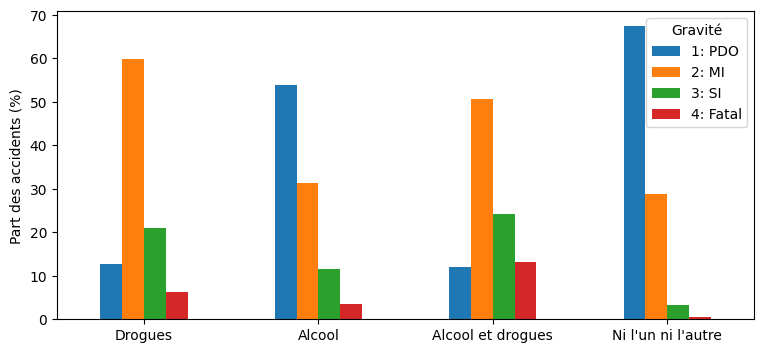

In [13]:
pourcentages.T.plot(kind="bar", rot=0, figsize=(9, 4))
plt.ylabel("Part des accidents (%)")
plt.xlabel("")
plt.legend(title="Gravité")
plt.show()

## 5. Comparaison RDD, DataFrame et SparkSQL

On écrit les deux mêmes requêtes avec les trois structures :

- **A** : pour chaque véhicule impliqué dans un accident à Adélaïde, la date, l'heure, le nombre de victimes, le sexe, l'âge et le type de permis du conducteur ;
- **B** : le nombre de victimes par commune quand un conducteur n'a pas de permis (même question qu'en 4.4).

Chaque fonction relit les fichiers CSV, pour que les trois versions fassent le même travail. On vérifie que les trois donnent exactement le même résultat, puis on mesure leur temps : chaque requête est lancée 3 fois et on garde le meilleur temps.

Dans l'article, les trois versions de la requête B ne calculent pas la même chose (filtres et agrégats différents). Ici elles suivent toutes la définition de la section 4.4.

In [14]:
def lire_tables_df():
    units = spark.read.csv("units_data/*.csv", header=True, escape='"')
    crash = spark.read.csv("crash_data/*.csv", header=True, escape='"')
    return units, crash

def lire_tables_rdd():
    units = sc.textFile("units_data/*.csv").filter(lambda l: l != units_header).map(lire_csv)
    crash = sc.textFile("crash_data/*.csv").filter(lambda l: l != crash_header).map(lire_csv)
    return units, crash

def normaliser(ligne):
    # une case vide vaut "" dans un RDD et None dans un DataFrame
    return tuple("" if v is None else v for v in ligne)

# ----- Requête A : véhicules impliqués dans un accident à Adélaïde
def requete_a_rdd():
    units, crash = lire_tables_rdd()
    accidents = (crash.filter(lambda r: r[C["Suburb"]] == "ADELAIDE")
                      .map(lambda r: (r[C["REPORT_ID"]], (r[C["Year"]] + "-" + r[C["Month"]] + "-" + r[C["Day"]],
                                                          r[C["Time"]], int(r[C["Total Cas"]])))))
    vehicules = units.map(lambda r: (r[U["REPORT_ID"]], (r[U["Sex"]], r[U["Age"]], r[U["Licence Type"]])))
    return sorted(a + v for _, (a, v) in accidents.join(vehicules).collect())

def requete_a_df():
    units, crash = lire_tables_df()
    resultat = (crash.filter(col("Suburb") == "ADELAIDE")
                     .join(units, "REPORT_ID")
                     .select(F.concat_ws("-", "Year", "Month", "Day"), "Time", col("Total Cas").cast("int"),
                             "Sex", "Age", "Licence Type"))
    return sorted(normaliser(r) for r in resultat.collect())

def requete_a_sql():
    units, crash = lire_tables_df()
    units.createOrReplaceTempView("units")
    crash.createOrReplaceTempView("crash")
    resultat = spark.sql("""
        SELECT concat_ws('-', c.Year, c.Month, c.Day), c.Time, CAST(c.`Total Cas` AS INT),
               u.Sex, u.Age, u.`Licence Type`
        FROM crash c JOIN units u ON c.REPORT_ID = u.REPORT_ID
        WHERE c.Suburb = 'ADELAIDE'
    """)
    return sorted(normaliser(r) for r in resultat.collect())

# ----- Requête B : victimes par commune quand un conducteur n'a pas de permis
def requete_b_rdd():
    units, crash = lire_tables_rdd()
    sans_permis = units.filter(lambda r: r[U["Licence Type"]] == "Unlicenced").map(lambda r: (r[U["REPORT_ID"]], 1))
    accidents = crash.map(lambda r: (r[C["REPORT_ID"]], (r[C["Suburb"]], int(r[C["Total Cas"]]))))
    return dict(sans_permis.join(accidents)
                           .map(lambda x: x[1][1])
                           .reduceByKey(lambda a, b: a + b)
                           .collect())

def requete_b_df():
    units, crash = lire_tables_df()
    resultat = (units.filter(col("Licence Type") == "Unlicenced")
                     .join(crash, "REPORT_ID")
                     .groupBy("Suburb")
                     .agg(F.sum(col("Total Cas").cast("int"))))
    return dict(normaliser(r) for r in resultat.collect())

def requete_b_sql():
    units, crash = lire_tables_df()
    units.createOrReplaceTempView("units")
    crash.createOrReplaceTempView("crash")
    resultat = spark.sql("""
        SELECT c.Suburb, SUM(CAST(c.`Total Cas` AS INT))
        FROM units u JOIN crash c ON u.REPORT_ID = c.REPORT_ID
        WHERE u.`Licence Type` = 'Unlicenced'
        GROUP BY c.Suburb
    """)
    return dict(normaliser(r) for r in resultat.collect())

In [15]:
def mesurer(fonction, essais=3):
    temps = []
    for _ in range(essais):
        debut = time.perf_counter()
        resultat = fonction()
        temps.append(time.perf_counter() - debut)
    return resultat, min(temps)

requetes = {
    "A (Adélaïde)": [requete_a_rdd, requete_a_df, requete_a_sql],
    "B (sans permis)": [requete_b_rdd, requete_b_df, requete_b_sql],
}
temps = {}
print(f"{'Requête':<16} {'RDD (s)':>8} {'DataFrame (s)':>14} {'SparkSQL (s)':>13}  Résultat")
for nom, fonctions in requetes.items():
    (r_rdd, t_rdd), (r_df, t_df), (r_sql, t_sql) = [mesurer(f) for f in fonctions]
    assert r_rdd == r_df == r_sql
    temps[nom] = [t_rdd, t_df, t_sql]
    print(f"{nom:<16} {t_rdd:>8.2f} {t_df:>14.2f} {t_sql:>13.2f}  {len(r_rdd)} lignes, identiques")

# la requête B donne bien le même résultat qu'en 4.4
assert r_rdd == {r["Suburb"]: r["Victimes"] for r in sans_permis_df.collect()}
print("\nLes trois structures donnent les mêmes résultats, et la requête B retrouve ceux de la section 4.4.")
spark.stop()

Requête           RDD (s)  DataFrame (s)  SparkSQL (s)  Résultat


A (Adélaïde)         0.52           0.28          0.25  11965 lignes, identiques


B (sans permis)      0.48           0.31          0.29  752 lignes, identiques



Les trois structures donnent les mêmes résultats, et la requête B retrouve ceux de la section 4.4.


## 6. Conclusion

Tous les résultats publiés dans l'article sont retrouvés : partitions, âge moyen, morts par type d'accident, victimes par commune avec un conducteur sans permis et gravité selon l'alcool et les drogues.

Ce que disent les données :

- l'âge moyen des conducteurs impliqués est le même pour les hommes et les femmes, environ 40 ans ;
- les sorties de route contre un obstacle fixe (`Hit Fixed Object`) sont le type d'accident le plus mortel : 245 morts sur la période ;
- les accidents avec alcool ou drogues sont beaucoup plus graves. La part d'accidents mortels passe de 0,42 % sans alcool ni drogues à 3,42 % avec alcool, 6,31 % avec drogues et 13,09 % avec les deux ; celle des blessés graves passe de 3,36 % à 11 à 24 %. Ces chiffres ne prouvent pas à eux seuls la cause : les dépistages sont sans doute plus systématiques après un accident grave.

Comparaison des trois structures : RDD, DataFrame et SparkSQL donnent exactement les mêmes résultats sur les deux requêtes. Les DataFrames et SparkSQL sont 1,5 à 2 fois plus rapides que les RDD (0,28 s contre 0,52 s pour la requête A), car Spark optimise leur requête et l'exécute directement dans la JVM, alors que les fonctions Python d'un RDD sont appliquées ligne par ligne dans des processus Python. DataFrame et SparkSQL ont des temps très proches : ce sont deux façons d'écrire la même requête, que Spark exécute de la même manière. Les DataFrames et SparkSQL sont aussi plus courts à écrire et plus lisibles.

Refaire l'étude a permis de corriger trois points de l'article : le découpage des lignes par `split(',')`, qui décale les colonnes de 17 % des accidents, le nom de la colonne utilisée pour le partitionnement, et les trois versions de la requête sur les conducteurs sans permis, qui ne calculaient pas la même chose.